<a href="https://colab.research.google.com/github/WesleyS-GH/DATA201-labs/blob/main/Assignments/Week9_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [93]:
%pip -q install ISLP

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ISLP import load_data
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

**Part 1**

In [95]:
carseats = load_data('Carseats')
carseats.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [96]:
# Convert Sales into categories: High = 1, Low = 0
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)
carseats = carseats.drop(columns=['Sales'])
print(carseats['HighSales'].value_counts())

HighSales
0    236
1    164
Name: count, dtype: int64


In [97]:
# Convert Yes, No to 1, 0
print(carseats['US'].value_counts())
print(carseats['Urban'].value_counts())

carseats['US'] = carseats['US'].map({
    'Yes': 1,
    'No': 0
})

print(carseats['US'].value_counts())

carseats['Urban'] = carseats['Urban'].map({
    'Yes': 1,
    'No': 0
})

print(carseats['Urban'].value_counts())

US
Yes    258
No     142
Name: count, dtype: int64
Urban
Yes    282
No     118
Name: count, dtype: int64
US
1    258
0    142
Name: count, dtype: int64
Urban
1    282
0    118
Name: count, dtype: int64


In [98]:
X = pd.get_dummies(carseats.drop(columns='HighSales'), columns=['ShelveLoc']).astype(int) # urban us
y = carseats['HighSales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=70, stratify=y)

print(X_train.shape, X_test.shape)
X_train.head()

(280, 12) (120, 12)


,CompPrice,Income,Advertising,Population,Price,Age,Education,Urban,US,ShelveLoc_Bad,ShelveLoc_Good,ShelveLoc_Medium
130,94,84,13,497,77,51,12,1,1,0,0,1
264,128,29,5,324,159,31,15,1,1,0,1,0
276,135,69,14,296,130,73,15,1,1,0,0,1
110,128,62,7,125,116,43,14,1,1,0,0,1
122,119,100,5,45,108,75,10,1,1,0,0,1


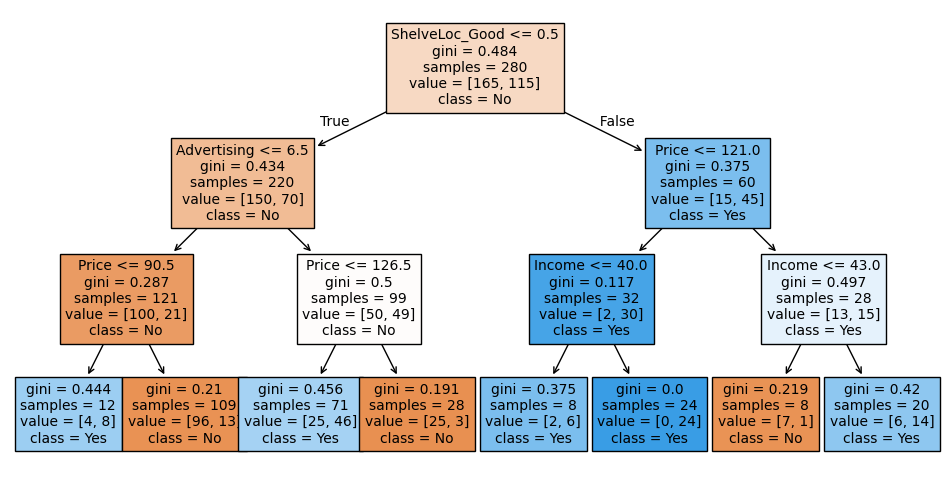

Train accuracy: 0.807
Test accuracy:  0.733


In [99]:
tree = DecisionTreeClassifier(max_depth=3, random_state=70)
tree.fit(X_train, y_train)

plt.figure(figsize=(12, 6))

plot_tree(tree,
          feature_names=list(X.columns),
          class_names=['No', 'Yes'],
          filled=True,
          fontsize=10)
plt.show()

print('Train accuracy:', round(tree.score(X_train, y_train), 3))
print('Test accuracy: ', round(tree.score(X_test, y_test), 3))

**Part 2**

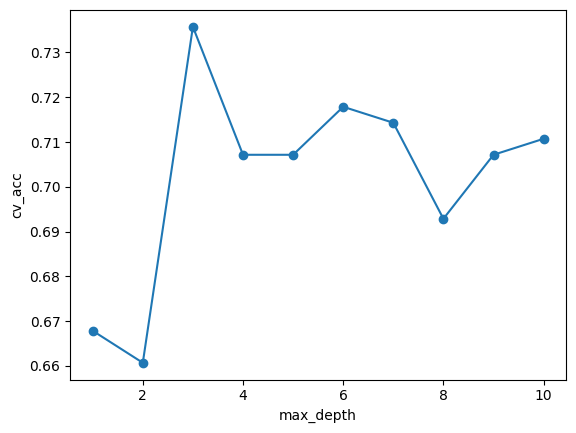

Best depth: 3
Test accuracy of pruned tree: 0.733


In [100]:
depths = range(1,11)

cv_acc = []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=70)
    cv_acc.append(cross_val_score(m, X_train, y_train, cv=5).mean())

plt.plot(depths, cv_acc, marker='o')
plt.xlabel('max_depth'); plt.ylabel('cv_acc')
plt.show()

best_depth = depths[int(np.argmax(cv_acc))]
pruned = DecisionTreeClassifier(max_depth=best_depth, random_state=70).fit(X_train, y_train)
print('Best depth:', round(best_depth, 4))
print('Test accuracy of pruned tree:', round(pruned.score(X_test, y_test), 3))

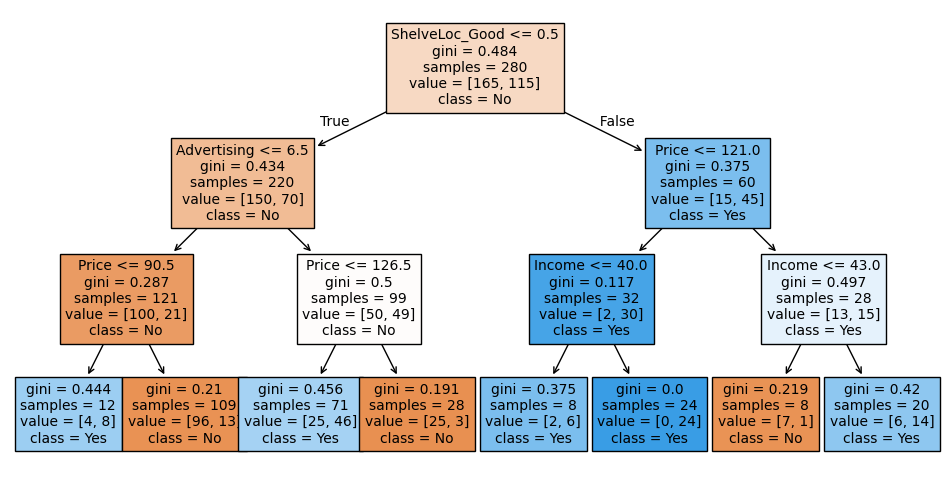

In [101]:
plt.figure(figsize=(12, 6))

plot_tree(pruned,
          feature_names=list(X.columns),
          class_names=['No', 'Yes'],
          filled=True,
          fontsize=10)
plt.show()

**Part 3**

1. Interpreting the tree: Which predictor was selected for the first split (root)? What does this split tell us about sales?

The predictor selceted for the first split was one of the encoded predictors, ShelveLoc_Good. This tells us that the predictor Shelveloc_Good carries the most weight in predicting a cars sales, as decision trees are greedy and try to find the best split, Shelveloc_Good is the best first split that the model found.


2. Choosing tree depth: According to your cross-validation graph, which depth performed best? Why should we use cross-validation rather than test accuracy to choose the depth?

According the the cv graph the depth that preformed the best was a depth of 3. We should use cv over test accuracy to choose the depth as it randomizes the data it is training on, since we only have one testing set we only get to see the outcome of each depth once, but with cv we can see multiple outcomes, or the mean of those outcomes, across the depths and get a better grasp of which depth is better.


3. Overfitting: Does increasing tree depth always improve cross-validation accuracy? Explain using your graph.

Increasing depth does not always improve cv accuracy, this is shown in the graph. A depth of 1 preformed better than a depth of 2, and a depth of 3 preformed better than any other depth present, which we values from 1-10. A depth of 3 have a cv accuracy of over 73% while no other depth had a cv accuracy over 72%. You can see this more as the depth increases, any depth from 4-7 had over 70% cv accuracy but when the depth increased to 8 it dropped to under 70%.

## 8. Wrap-up questions

Answer in your own words in a text cell.

1. What does a leaf predict in a classification tree? In a regression tree?
2. Why did the full tree reach 100% training accuracy but do worse on the test set?
3. Give two ways to limit tree complexity. Which one did cross-validation help you tune?
4. Why do we not need to scale features before fitting a tree?
5. A teammate says "`Age` has importance 0, so it is irrelevant to heart disease." What is wrong with that claim? (answer in terms of reducing impurity)
6. Name one strength and one weakness of a single decision tree that you saw in this lab.

1. In a classification tree each leaf predicts the most common class present. In a regression tree each leaf predicts the mean responses based on the training data that went through that leaf.

2. Because the tree overfit and memorized the training set. When letting the tree grow to its fullest it memorizes the training set and makes it where every leaf is pure, this makes the model have 100% accuracy on the training, but since it has memorized the training data it is going to struggle on the testing data since it isn't data it has memorized.

3. To limit tree complexity you can either pre-prune, and limit how much the tree grows before hand, or post-prune and remove branches from the tree after it was made. Cross validation can be used to help tune both pre and post pruning by helping you find the best hyperparameter. For pre-pruning this can be the depth, max leaves, and minimum number of samples in each leaf, and for post-pruning this is the alpha that control the post-pruning.

4. We don't need to scale the features before fitting a tree because each variable is looked at one at a time and because of that one variable having higher average values than another doesn't make it seem like it hold more weight or say in a prediction.

5. Feature importance doesn't tell us if a predictor is actually useful or not all it tells us is how much it was used. Just because age has an importance of 0 doesn't mean its useless, a predictor may be looked over by the model since another predictor already gives it the same information. Importance tells us the models reliance on certain predictors but it doesn't tell us which are irrelevant to the case.

6. A strength in this lab was preforming a pre-pruning process in the depth of the tree, as this helped better tune the model to see which depth would be the most effective when using this model for new unseen data. But I feel like a weakness that needs to be addressed is the lack of the use of other pre-pruning methods, I didn't mention post-pruning since it can be resource intesive, but if we were to use other pre-pruning methods like max leaf nodes or min leaf samples we could see if those methods would help us better classify the samples in this model.